# Record repair and blind novelty re-check: stage 0c, movability

This notebook runs one stage of `eval.py`, the script of the evaluation artifact *Record repair and blind novelty re-check* (iteration 6, Step 0 of the run). The research behind it asks whether an instruction-tuned LLM can be made to write a different algorithm from its default one. Asked to implement a path search, for example, Qwen3-8B nearly always writes BFS or Dijkstra.

**What the whole script does.** `eval.py` is CPU-only and runs no model. It recomputes, from rows that earlier experiments stored, every number that the iteration-6 repair of the run's report touches. It writes each change to the report as a verbatim `old_text` → `new_text` correction. Its stages are:

| Stage | What it does | Here? |
|-|-|-|
| s0 | hashes every input, indexes the report | no |
| 0a | 8-bit against bf16 engine contrasts, dose units, engine tags, the like-for-like figure | no |
| 0b | landing tallies, the confound subset, the twin's own alternative as a rival | no |
| **0c** | **movability: does the base model's repertoire predict which tasks a random push moves?** | **yes** |
| 0d, 0e | missing tables, minor fixes | no |
| 0f | second blind novelty adjudication (sandbox stress tests, tree edit distance, LLM judges) | no |
| audit, out | independent re-derivation; `eval_out.json` | no |

The other stages read many files from eight earlier experiment artifacts, run sandboxed programs or call LLM judges. Stage 0c needs only the 15 task units it analyses, and `mini_demo_data.json` carries them.

**The question of stage 0c.** Each of 13 new tasks (6 in panel A, 7 in panel B, all on Qwen3-8B) has two measured numbers:

- **beta**: the share of the *base* (untuned) model's correct programs that use an algorithm other than the instruct model's default. A high beta means the base model knows several ways to solve the task.
- **E**, the escape fraction: the share of 8 fixed random *plan-noise* directions that move the instruct model off its default.
  - A direction is added to the model's hidden states at blocks 12 to 23 while it reads the task.
  - It *escapes* when it raises off-default attempts by at least 0.20 over the unpushed model, at a pass rate of at least 0.8 times that model's.
  - E is averaged over doses 1 and 2.

The registered claim was that beta ranks E at a Spearman of at least 0.6; below 0.3 it counted as disconfirmed. Stage 0c measures that correlation with exact small-sample statistics, then writes the report corrections that quote the numbers.

**Result of the full run:**
- Spearman 0.146 over the 13 units, Bonett-Wright 95% interval [-0.44, 0.65].
- Power at a true 0.6 is only 0.63, so a moderate relation is not excluded either.
- Of five rival predictors, only the runtime merit R6 tracks movability (Spearman 0.71, Holm p 0.021).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- eval.py's import block ----
import argparse
import gc
import json
import math
import resource
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
from loguru import logger

# eval.py then imports its helper modules from the artifact's src/ package:
#     from src import common as C
#     from src import xstats as X
# The parts of both that stage 0c uses are copied into the cells below and gathered under the same names, C and X.

# ---- imports of src/common.py and src/xstats.py ----
import hashlib
import os
from typing import Any, Sequence

from scipy import stats as st

# ---- notebook additions ----
import textwrap
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-6/evaluation-5/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"{len(data['examples'])} units:", ", ".join(f"{r['unit']} {r['name']}" for r in data["examples"]))

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Demo data for stage 0c (movability) of the iteration-6 record repair, artifact art_aRTQM6CQ0Dre. One dataset: the 15 new task units of panels A and B (13 core units plus the reserve units A8 and A9), each row exactly as eval.py's movability_units() built it in the full run.
15 units: A1 majority element, A2 maximum block sum, A3 trapped rain water, A4 count primes, A5 longest common prefix, A7 longest mirrored substring, A8 jump game, A9 median of two sorted lists, B1 missing number, B2 single number, B3 minimum spanning tree weight, B4 integer square root, B5 all subsets, B6 valid anagram, B7 count inversions


## Configuration

Stage 0c is cheap apart from its resampling. Every count that drives its runtime is set below, and the comment on each line gives the value of the full run (`uv run eval.py --stages all`, defaults `--n-boot 10000 --n-power 10000`). The seeds stay fixed inside the code as in `eval.py`, so the full-run counts reproduce the artifact's numbers exactly. With them, stage 0c takes about 10 seconds on a CPU.

Smaller counts leave rho and the three Fisher-z intervals exactly as they are. They make the permutation p values (the rivals' Holm p included), the bootstrap intervals and the power figures noisier.

In [5]:
# Resampling counts of stage 0c, set to the values of the full run (uv run eval.py --stages all); with them the stage
# takes about 10 s on a CPU. For a quicker look divide them by 10 or 100: rho and the Fisher-z intervals do not change.
N_BOOT = 10000             # unit-bootstrap replicates for the rho interval and the rival deltas (eval.py --n-boot 10000)
N_POWER = 10000            # Gaussian-copula power replicates at a true rho of 0.6 (eval.py --n-power 10000)
N_PERM_MAIN = 1_000_000    # Monte Carlo permutations for the registered one-sided rho test (eval.py: 1_000_000)
N_PERM_SENS = 200_000      # permutations for each sensitivity check and each rival (eval.py: 200_000)
N_POWER_SIDE_MIN = 2000    # floor on the replicates for the power at rho 0.4 and 0.8, used as max(floor, N_POWER // 4) (eval.py: 2000)
N_REP_CURVE = 2000         # replicates per sample size on the power-against-n curve (eval.py: 2000)
N_PERM_CURVE = 1000        # permutations per replicate on that curve (eval.py: 1000)

## Shared helpers (`src/common.py`)

`eval.py` keeps its infrastructure in `src/common.py`. Stage 0c uses four parts of it:

- **Provenance strings** (`prov`) tag every value with `<artifact_id>:<path>#<pointer>`.
- **Value statuses** (`val`, `status_of`) compare a number the report recorded with the recomputed one:
  - MATCH: within a tolerance set per kind (0.005 for a rho or a share);
  - CORRECTED: outside that tolerance;
  - NEW: the report had no number;
  - CARRIED: nothing was recomputed.
- **The report index** (`Report`) finds the line and section of a passage.
- **The corrections ledger** (`Ledger`) accepts a correction only if its `old_text` occurs exactly once in the report.

The code is copied as it is, with three changes for the notebook, each marked `# Notebook:` in the cell:
1. `WS`, the folder outputs go to, is a local `eval_demo_outputs/` folder instead of the artifact folder.
2. The loaders of dependency-artifact files are left out, because the inputs come from `mini_demo_data.json`.
3. `read_result()` returns stage 0a's result from the data file, because stage 0a does not run here.

In [6]:
# ==== src/common.py: the parts stage 0c uses ====
"""Shared infrastructure: dependency resolution by artifact id, provenance strings, input hashing, report index,
value statuses and the corrections ledger. No absolute server path is written into any output file."""

# Notebook: outputs go to a local folder (eval.py: WS = Path(__file__).resolve().parent.parent, the artifact folder)
WS = Path("eval_demo_outputs").resolve()
RESULTS = WS / "results"
TABLES = WS / "tables"
FIGURES = WS / "figures"
AUDIT = WS / "audit"
LOGS = WS / "logs"
for _d in (RESULTS, TABLES, FIGURES, AUDIT, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# artifact id -> original workspace folder of the artifact (relative to AII_DEPS_ROOT in the run's own layout)
DEPS = {
    "art_ccAbfJVcv0LO": "iter_3/gen_art/gen_art_experiment_18",
    "art_mWn-MQEnNelg": "iter_4/gen_art/gen_art_experiment_19",
    "art_SHaWv77P1XCI": "iter_4/gen_art/gen_art_experiment_22",
    "art_CcZLW-9NX00l": "iter_5/gen_art/gen_art_experiment_24",
    "art_8WbrpoEFslk9": "iter_5/gen_art/gen_art_experiment_25",
    "art_9a8LrIv2lHbV": "iter_5/gen_art/gen_art_experiment_26",
    "art_jR6Pyy3W9xum": "iter_5/gen_art/gen_art_experiment_27",
    "art_hG0QPiaIPNhP": "iter_5/gen_art/gen_art_experiment_28",
    # read by absolute path as the direction instructs (evaluations cannot be declared dependencies)
    "art_mgek9PfVBNbh": "iter_5/gen_art/gen_art_evaluation_4",
    "art_sV0cQ3ef1ZRQ": "iter_4/gen_art/gen_art_evaluation_3",
}
NICK = {"D18": "art_ccAbfJVcv0LO", "D19": "art_mWn-MQEnNelg", "D22": "art_SHaWv77P1XCI",
        "D24": "art_CcZLW-9NX00l", "PA": "art_8WbrpoEFslk9", "PB": "art_9a8LrIv2lHbV",
        "D27": "art_jR6Pyy3W9xum", "GEM": "art_hG0QPiaIPNhP", "EV4": "art_mgek9PfVBNbh", "EV3": "art_sV0cQ3ef1ZRQ"}


# ONE location setting for every input another artifact produced: AII_DEPS_ROOT. By default it is the folder that
# holds this artifact in the published repository (WS.parent), where the dependencies are sibling folders. A dependency
# folder is looked up by its artifact id first, then by its original workspace name. Two small evaluations that are
# not declared dependencies (art_mgek9PfVBNbh, art_sV0cQ3ef1ZRQ) are vendored under inputs/<artifact_id>/ as a fallback.
DEPS_ROOT = Path(os.environ.get("AII_DEPS_ROOT", str(WS.parent)))
# The report the corrections are keyed to, vendored from the strategy step of iteration 6.
REPORT_PATH = Path(os.environ.get("AII_REPORT", str(WS / "inputs" / "report" / "current_report.md")))
CFG = {"aii_json_skill_dir": os.environ.get("AII_JSON_SKILL_DIR", "")}

HASHES: dict[str, str] = {}


def aid_of(nick_or_aid: str) -> str:
    return NICK.get(nick_or_aid, nick_or_aid)


# Notebook: dep_dir(), dep_path(), sha256_file(), _record(), load_json(), load_jsonl(), iter_jsonl(), read_text() and
# exists() read files of the dependency artifacts. Stage 0c's inputs come from mini_demo_data.json, so they are left out.


def prov(nick_or_aid: str, rel: str, ptr: str | None = None) -> str:
    s = f"{aid_of(nick_or_aid)}:{rel}"
    return s + (f"#{ptr}" if ptr else "")


# ------------------------------------------------------------------------------------------------ outputs
def jdump(obj: Any) -> str:
    return json.dumps(obj, indent=1, default=_default, allow_nan=False)


def _default(o: Any):
    import numpy as np
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o.relative_to(WS)) if str(o).startswith(str(WS)) else o.name
    raise TypeError(type(o))


def clean_nan(o: Any) -> Any:
    if isinstance(o, float):
        return None if not math.isfinite(o) else o
    if isinstance(o, dict):
        return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def write_json(rel: str, obj: Any) -> Path:
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(jdump(clean_nan(obj)))
    return p


def read_result(name: str) -> Any:
    # Notebook: eval.py reads the results/<name>.json an earlier stage wrote,
    #     return json.loads((RESULTS / f"{name}.json").read_text())
    # Stage 0a does not run here, so its result (the engine tag of each task) comes from mini_demo_data.json.
    return data["upstream"][f"results_{name}"]


def write_csv(rel: str, rows: list[dict], cols: list[str] | None = None) -> Path:
    import csv
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    cols = cols or list(dict.fromkeys(k for r in rows for k in r.keys()))
    with p.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: _csv_cell(r.get(k)) for k in cols})
    return p


def _csv_cell(v: Any) -> Any:
    if isinstance(v, float):
        return "" if not math.isfinite(v) else round(v, 6)
    if isinstance(v, (dict, list, tuple)):
        return json.dumps(clean_nan(v))
    return v


# ------------------------------------------------------------------------------------------------ statuses
TOL = {"count": 0.0, "share": 0.005, "p": 0.10, "hill": 0.02, "ratio": 0.005, "nats": 0.01, "rho": 0.005,
       "label": None, "text": None}


def status_of(recorded: Any, recomputed: Any, kind: str) -> str:
    if recorded is None:
        return "NEW"
    if recomputed is None:
        return "CARRIED"
    if kind in ("label", "text"):
        return "MATCH" if str(recorded) == str(recomputed) else "CORRECTED"
    if isinstance(recorded, (list, tuple)):
        if not isinstance(recomputed, (list, tuple)) or len(recorded) != len(recomputed):
            return "CORRECTED"
        return "MATCH" if all(status_of(a, b, kind) == "MATCH" for a, b in zip(recorded, recomputed)) \
            else "CORRECTED"
    try:
        a, b = float(recorded), float(recomputed)
    except (TypeError, ValueError):
        return "MATCH" if recorded == recomputed else "CORRECTED"
    if kind == "count":
        return "MATCH" if abs(a - b) < 1e-9 else "CORRECTED"
    if kind == "p":
        return "MATCH" if abs(a - b) <= TOL["p"] * max(abs(a), 1e-12) + 1e-12 else "CORRECTED"
    return "MATCH" if abs(a - b) <= TOL.get(kind, 0.005) + 1e-12 else "CORRECTED"


def val(name: str, recorded: Any, recomputed: Any, source: str, kind: str = "share",
        status: str | None = None, note: str | None = None) -> dict:
    s = status or status_of(recorded, recomputed, kind)
    d = {"name": name, "recorded": recorded, "recomputed": recomputed, "status": s, "source": source,
         "tolerance": kind}
    if note:
        d["note"] = note
    return d


# ------------------------------------------------------------------------------------------------ report
class Report:
    def __init__(self, path: Path):
        self.text = path.read_text()
        self.lines = self.text.split("\n")
        self.sha256 = hashlib.sha256(self.text.encode()).hexdigest()

    def line_of(self, s: str) -> int | None:
        """1-based line where s first starts (s may span lines)."""
        i = self.text.find(s)
        if i < 0:
            return None
        return self.text.count("\n", 0, i) + 1

    def count(self, s: str) -> int:
        return self.text.count(s)

    def line(self, n: int) -> str:
        return self.lines[n - 1]

    def section_of(self, n: int) -> str:
        for k in range(n - 1, -1, -1):
            if self.lines[k].startswith("#"):
                return self.lines[k].lstrip("#").strip()[:80]
        return ""

    def table_block(self, caption_prefix: str) -> tuple[int, list[str]]:
        """Return (1-based first row line, rows) of the markdown table following the caption line."""
        n = self.line_of(caption_prefix)
        if n is None:
            raise KeyError(caption_prefix)
        k = n  # 0-based index of the line after the caption
        while k < len(self.lines) and not self.lines[k].startswith("|"):
            k += 1
        start = k
        rows = []
        while k < len(self.lines) and self.lines[k].startswith("|"):
            rows.append(self.lines[k])
            k += 1
        return start + 1, rows


class Ledger:
    """Corrections keyed to exact substrings of current_report.md."""

    def __init__(self, report: Report):
        self.rep = report
        self.items: list[dict] = []

    def add(self, review_item: str, old_text: str, new_text: str, values: list[dict] | None = None,
            note: str | None = None) -> dict:
        n = self.rep.line_of(old_text)
        if n is None:
            raise ValueError(f"old_text not found in report for {review_item}: {old_text[:80]!r}")
        if self.rep.count(old_text) != 1:
            raise ValueError(f"old_text not unique ({self.rep.count(old_text)}) for {review_item}: {old_text[:80]!r}")
        item = {"id": f"C6-{len(self.items) + 1:03d}", "review_item": review_item,
                "location": {"section": self.rep.section_of(n), "report_line": n},
                "old_text": old_text, "new_text": new_text, "values": values or [],
                "marker": "iteration-6 correction"}
        if note:
            item["note"] = note
        self.items.append(item)
        return item


# Notebook: gather the names under the module alias eval.py uses (`from src import common as C`)
C = types.SimpleNamespace(WS=WS, RESULTS=RESULTS, TABLES=TABLES, FIGURES=FIGURES, AUDIT=AUDIT, LOGS=LOGS, DEPS=DEPS,
                          NICK=NICK, DEPS_ROOT=DEPS_ROOT, REPORT_PATH=REPORT_PATH, CFG=CFG, HASHES=HASHES,
                          aid_of=aid_of, prov=prov, jdump=jdump, clean_nan=clean_nan, write_json=write_json,
                          read_result=read_result, write_csv=write_csv, TOL=TOL, status_of=status_of, val=val,
                          Report=Report, Ledger=Ledger)

## Exact small-sample statistics (`src/xstats.py`)

These are the functions stage 0c calls, copied as they are:

- **`spearman` and `spearman_perm_p`**: Spearman rho, and its permutation p with mid-ranks for ties. With 13 units, exact enumeration would take 13! ≈ 6.2e9 permutations, so the p uses Monte Carlo permutations, with the usual +1 correction.
- **`fisher_z_ci`**: three Fisher-z intervals for rho, which differ only in the standard error:
  - plain: 1/√(n−3);
  - Fieller: √(1.06/(n−3));
  - Bonett-Wright: √((1 + rho²/2)/(n−3)).
- **`bootstrap_spearman`**: resamples the units. It gives a percentile interval and a bias-corrected and accelerated (BCa) interval, with the acceleration taken from a jackknife. Resamples where beta or E is constant are dropped.
- **`copula_power`**: the power of the one-sided permutation test at a true Spearman `rho_s`. It simulates pairs from a Gaussian copula with latent Pearson r = 2·sin(π·rho_s/6). Each margin goes through the inverse empirical CDF of the observed beta and E, which keeps their ties and zeros.
- **`holm`**: the Holm step-down adjustment over the five rivals.

In [7]:
# ==== src/xstats.py: the functions stage 0c calls ====
"""Exact small-sample statistics used by eval.py (numpy/scipy). audit/rederive.py re-implements them in stdlib."""


# ----------------------------------------------------------------------------------------- proportions
def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out


# ----------------------------------------------------------------------------------------- rank correlation
def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    r = st.spearmanr(x, y).statistic
    return float(r) if np.isfinite(r) else math.nan


def _rank(a: np.ndarray) -> np.ndarray:
    return st.rankdata(a, axis=-1)


def spearman_perm_p(x: Sequence[float], y: Sequence[float], n_perm: int = 1_000_000, seed: int = 0,
                    alternative: str = "greater") -> dict:
    """Permutation p for Spearman with ties (mid-ranks). Exact enumeration when n! <= 2e6, else Monte Carlo."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    rx, ry = _rank(x), _rank(y)
    obs = spearman(x, y)
    if math.factorial(n) <= 2_000_000:
        from itertools import permutations
        perms = np.array(list(permutations(range(n))))
        method = "exact enumeration"
    else:
        rng = np.random.default_rng(seed)
        perms = np.argsort(rng.random((n_perm, n)), axis=1)
        method = f"Monte Carlo, {n_perm} permutations"
    ryp = ry[perms]
    rxc = rx - rx.mean()
    rypc = ryp - ryp.mean(axis=1, keepdims=True)
    den = np.sqrt((rxc ** 2).sum() * (rypc ** 2).sum(axis=1))
    rho = np.where(den > 0, (rypc * rxc).sum(axis=1) / np.where(den > 0, den, 1), 0.0)
    eps = 1e-12
    if alternative == "greater":
        p = float((rho >= obs - eps).mean())
    elif alternative == "less":
        p = float((rho <= obs + eps).mean())
    else:
        p = float((np.abs(rho) >= abs(obs) - eps).mean())
    if method.startswith("Monte"):
        p = (p * len(perms) + 1) / (len(perms) + 1)
    return {"rho": obs, "p": p, "method": method, "alternative": alternative}


def fisher_z_ci(r: float, n: int, se_kind: str = "plain", conf: float = 0.95) -> tuple[float, float]:
    z = math.atanh(max(min(r, 0.999999), -0.999999))
    if se_kind == "plain":
        se = 1 / math.sqrt(n - 3)
    elif se_kind == "fieller":
        se = math.sqrt(1.06 / (n - 3))
    elif se_kind == "bonett_wright":
        se = math.sqrt((1 + r * r / 2) / (n - 3))
    else:
        raise ValueError(se_kind)
    q = float(st.norm.ppf(1 - (1 - conf) / 2))
    return (math.tanh(z - q * se), math.tanh(z + q * se))


def bootstrap_spearman(x: Sequence[float], y: Sequence[float], n_boot: int = 10_000, seed: int = 0) -> dict:
    """Unit bootstrap: percentile and BCa intervals; degenerate resamples (constant margin) are dropped."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    vals = np.array([_spearman_fast(x[i], y[i]) for i in idx])
    ok = np.isfinite(vals)
    v = vals[ok]
    obs = spearman(x, y)
    pct = (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975)))
    # BCa
    z0 = float(st.norm.ppf(max(min((v < obs).mean() + 0.5 * (v == obs).mean(), 1 - 1e-9), 1e-9)))
    jack = np.array([spearman(np.delete(x, i), np.delete(y, i)) for i in range(n)])
    jack = jack[np.isfinite(jack)]
    jm = jack.mean()
    num = ((jm - jack) ** 3).sum()
    den = 6 * (((jm - jack) ** 2).sum()) ** 1.5
    a = float(num / den) if den > 0 else 0.0
    out = []
    for q in (0.025, 0.975):
        zq = float(st.norm.ppf(q))
        adj = st.norm.cdf(z0 + (z0 + zq) / (1 - a * (z0 + zq)))
        out.append(float(np.quantile(v, min(max(adj, 0.0), 1.0))))
    return {"n_boot": n_boot, "n_valid": int(ok.sum()), "percentile": pct, "bca": tuple(out), "z0": z0, "a": a,
            "samples": vals}


def _spearman_fast(a: np.ndarray, b: np.ndarray) -> float:
    if np.all(a == a[0]) or np.all(b == b[0]):
        return math.nan
    ra, rb = _rank(a), _rank(b)
    ra = ra - ra.mean()
    rb = rb - rb.mean()
    return float((ra * rb).sum() / math.sqrt((ra ** 2).sum() * (rb ** 2).sum()))


def copula_power(x: Sequence[float], y: Sequence[float], rho_s: float, n: int, n_rep: int = 10_000,
                 alpha: float = 0.05, n_perm: int = 2000, seed: int = 0) -> dict:
    """Power of the one-sided permutation Spearman test under a Gaussian copula with empirical margins.

    Pearson r of the latent normals = 2 sin(pi * rho_s / 6); margins through the inverse empirical CDF (keeps ties).
    The permutation null is evaluated with n_perm permutations per replicate (shared permutation matrix)."""
    x = np.sort(np.asarray(x, float))
    y = np.sort(np.asarray(y, float))
    r = 2 * math.sin(math.pi * rho_s / 6)
    rng = np.random.default_rng(seed)
    cov = np.array([[1.0, r], [r, 1.0]])
    z = rng.multivariate_normal([0, 0], cov, size=(n_rep, n))
    u = st.norm.cdf(z)
    # inverse empirical CDF: ceil(u * m) - 1
    xi = np.minimum((u[..., 0] * len(x)).astype(int), len(x) - 1)
    yi = np.minimum((u[..., 1] * len(y)).astype(int), len(y) - 1)
    X, Y = x[xi], y[yi]
    perms = np.argsort(rng.random((n_perm, n)), axis=1)
    rej, rej2, n_def = 0, 0, 0
    for i in range(n_rep):
        a, b = X[i], Y[i]
        if np.all(a == a[0]) or np.all(b == b[0]):
            continue  # constant margin: test undefined, counted as non-rejection
        ra, rb = _rank(a), _rank(b)
        ra = ra - ra.mean()
        rbp = rb[perms]
        rbp = rbp - rbp.mean(axis=1, keepdims=True)
        rb0 = rb - rb.mean()
        dena = (ra ** 2).sum()
        obs = (ra * rb0).sum() / math.sqrt(dena * (rb0 ** 2).sum())
        null = (rbp * ra).sum(axis=1) / np.sqrt(dena * (rbp ** 2).sum(axis=1))
        p = ((null >= obs - 1e-12).sum() + 1) / (n_perm + 1)
        p2 = ((np.abs(null) >= abs(obs) - 1e-12).sum() + 1) / (n_perm + 1)
        n_def += 1
        rej += p <= alpha
        rej2 += p2 <= alpha
    return {"rho_s": rho_s, "pearson_latent": r, "n": n, "n_rep": n_rep, "n_defined": n_def,
            "power": rej / n_rep, "power_two_sided": rej2 / n_rep, "mc_se": math.sqrt(max(rej / n_rep * (1 - rej / n_rep), 1e-12) / n_rep)}


# Notebook: gather the functions under the module alias eval.py uses (`from src import xstats as X`)
X = types.SimpleNamespace(holm=holm, spearman=spearman, spearman_perm_p=spearman_perm_p, fisher_z_ci=fisher_z_ci,
                          bootstrap_spearman=bootstrap_spearman, _spearman_fast=_spearman_fast, copula_power=copula_power)

## `eval.py`: module header

This cell is the script's own top level, copied as it is:
- logging to stdout and to `logs/run.log`;
- the names of the existing tasks (`TNAME`) and of the new units (`UNAME`);
- the global `REPORT` and `LEDGER`, which `main()` fills in;
- the small helpers. `fmtp` prints a p value below 0.001 in scientific notation and others to three decimals, and `save_stage` writes `results/<stage>.json`.

In [8]:
"""Iteration-6 Step 0 (CPU only): record repair of the run's report.

Stages: s0 (inputs, hashes, report index), 0a (engine and dose), 0b (landings), 0c (movability), 0d (missing
tables), 0e (minor), 0f (second blind novelty adjudication; src/adjudicate.py), audit (audit/rederive.py),
out (eval_out.json, corrections.json, tables, README checks).  Run: uv run eval.py --stages all
"""

WS = C.WS
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(C.LOGS / "run.log"), rotation="30 MB", level="DEBUG")

DECISIVE = ["T03", "T10", "T2", "T05", "T1"]
TNAME = {"T1": "grid", "T2": "shortest path", "T03": "kth smallest", "T04": "substring search", "T05": "two sum",
         "T06": "find duplicate", "T08": "Fibonacci", "T10": "connected components",
         "T11": "longest increasing subsequence", "T13": "merge intervals", "T14": "top-k frequent",
         "R1": "non-overlapping intervals", "R2": "cycle detection", "R3": "topological order",
         "R6": "first and last position"}
NEW_UNITS_A = ["A1", "A2", "A3", "A4", "A5", "A7"]
NEW_UNITS_B = ["B1", "B2", "B3", "B4", "B5", "B6", "B7"]
UNAME = {"A1": "majority element", "A2": "maximum block sum", "A3": "trapped rain water", "A4": "count primes",
         "A5": "longest common prefix", "A7": "longest mirrored substring", "A8": "jump game",
         "A9": "median of two sorted lists", "B1": "missing number", "B2": "single number",
         "B3": "minimum spanning tree weight", "B4": "integer square root", "B5": "all subsets",
         "B6": "valid anagram", "B7": "count inversions"}
REPORT: C.Report | None = None
LEDGER: C.Ledger | None = None


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None or (isinstance(x, float) and not math.isfinite(x)):
        return "n/a"
    return f"{x:.{nd}f}"


def fmtp(p: float | None) -> str:
    if p is None or not math.isfinite(p):
        return "n/a"
    if p < 0.001:
        return f"{p:.1e}"
    return f"{p:.3f}"


def join_and(xs: list[str]) -> str:
    xs = list(xs)
    if not xs:
        return "no task"
    return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]


def save_stage(name: str, obj: dict) -> None:
    C.write_json(f"results/{name}.json", obj)
    logger.info(f"stage {name}: wrote results/{name}.json")

## The dataset: 15 task units

In `eval.py`, `movability_units()` builds one row per new task unit from the two panel artifacts:
- each panel's `pooled_inputs.json` gives beta, E, the rivals and the instruct twin's composition;
- each unit's `tests.jsonl` gives the stored reference timings, from which `_unit_tests_runtime()` derives the runtime merit R6.

Those files are not bundled. Instead, the stand-in below returns the 15 rows the function built in the full run (`results/0c.json` → `units`, carried in `mini_demo_data.json`). Each row keeps `R6_detail`, so R6 can be checked by hand: R6 = log(`t_default` / `t_fastest`). For reference, the original code is:

```python
def _unit_tests_runtime(nick: str, folder: str, default: str, catalogue: list[str]) -> dict:
    rows = C.load_jsonl(nick, f"{folder}/tests.jsonl")
    tot: dict[str, float] = {}
    stress_logr: dict[str, list[float]] = {}
    for r in rows:
        rt = r.get("ref_times")
        if isinstance(rt, str):
            import ast as _ast
            rt = _ast.literal_eval(rt)
        if not rt:
            continue
        for m, v in rt.items():
            tot[m] = tot.get(m, 0.0) + float(v)
        if r.get("kind") == "stress" and default in rt:
            for m, v in rt.items():
                if m != default:
                    stress_logr.setdefault(m, []).append(math.log(max(float(v), 1e-6) / max(float(rt[default]), 1e-6)))
    alts = [m for m in catalogue if m != default and m in tot]
    if default not in tot or not alts:
        return {"R6": None, "n_cases": len(rows)}
    fastest = min(alts, key=lambda m: tot[m])
    gm = {m: math.exp(sum(v) / len(v)) for m, v in stress_logr.items() if v and m in alts}
    return {"R6": math.log(tot[default] / max(tot[fastest], 1e-9)), "fastest": fastest, "t_default": tot[default],
            "t_fastest": tot[fastest], "n_cases": len(rows), "modes_timed": sorted(tot),
            "R6_stress_gm_variant": (-math.log(min(gm.values()))) if gm else None}


def movability_units() -> list[dict]:
    pa = {u["unit_id"]: u for u in C.load_json("PA", "pooled_inputs.json")["units"]}
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    nb = sorted(p.name for p in C.dep_path("PA", "newbench").iterdir() if p.is_dir())
    rows = []
    for u in NEW_UNITS_A + ["A8", "A9"]:
        x = pa[u]
        folder = "newbench/" + next(n for n in nb if n.startswith(u + "_"))
        rt = _unit_tests_runtime("PA", folder, x["default"], x["catalogue"])
        r = x["rivals"]
        twin_off = 1 - x["twin"]["comp_correct"].get(x["default"], 0) / max(x["twin"]["n_correct"], 1)
        rows.append({"unit": u, "panel": "A", "name": UNAME[u], "core13": u not in ("A8", "A9"),
                     "beta": x["base"]["beta"], "beta_source": "correct (chat)", "beta_correct_only": x["base"]["beta"],
                     "E": x["escape"]["E"], "R1_opening_margin": r["opening_margin"],
                     "R4_novelty_excess": r["novelty_excess"], "R7_twin_modal_share": r["twin_modal_share"],
                     "K": r["K"], "R6_runtime_merit": rt["R6"], "R6_detail": rt,
                     "R6_recorded_panel_definition": r["merit_runtime_min"],
                     "twin_offdef": twin_off, "twin_default_share": x["default_share"],
                     "source": C.prov("PA", "pooled_inputs.json", f"/units/{u}") + "; " + C.prov("PA", folder + "/tests.jsonl")})
    for u in NEW_UNITS_B:
        x = pb[u]
        d = x["unit_facts"]["default"]
        rt = _unit_tests_runtime("PB", f"units/{u}", d, x["unit_facts"]["catalogue"])
        r = x["rivals"]
        tw = x["twin"]["correct_composition"]
        twin_off = 1 - tw.get(d, 0) / max(sum(tw.values()), 1)
        rows.append({"unit": u, "panel": "B", "name": UNAME[u], "core13": True, "beta": x["base"]["beta_u"],
                     "beta_source": x["base"].get("beta_source"), "beta_correct_only": x["base"].get("beta_correct"),
                     "other_share_of_attempts": (x["base"]["attempted_composition"].get("other", 0) /
                                                 max(sum(x["base"]["attempted_composition"].values()), 1)),
                     "E": x["outcomes"]["E_u"], "R1_opening_margin": r["R_margin"],
                     "R4_novelty_excess": (r["R_novel"] - r["R_modal"]) if r.get("R_novel") is not None else None,
                     "R7_twin_modal_share": 1 - r["R_modal"], "K": r["K_u"], "R6_runtime_merit": rt["R6"],
                     "R6_detail": rt, "R6_recorded_panel_definition": r["R_merit_runtime"],
                     "twin_offdef": twin_off, "twin_default_share": max(tw.values()) / max(sum(tw.values()), 1),
                     "source": C.prov("PB", "pooled_inputs.json", f"/records/{u}") + "; " + C.prov("PB", f"units/{u}/tests.jsonl")})
    return rows
```

In [9]:
def movability_units() -> list[dict]:
    """Notebook stand-in for eval.py's movability_units(): the 15 rows it built in the full run, from mini_demo_data.json."""
    return [dict(r) for r in data["examples"]]


# The 13 registered units, then the reserve units A8 and A9
print(f"{'unit':<5}{'name':<30}{'core':>5}{'beta':>7}{'beta c-o':>9}{'E':>7}{'R1':>8}{'R4':>7}{'R6':>7}{'R7':>6}{'K':>4}")
for r in sorted(movability_units(), key=lambda r: (not r["core13"], r["unit"])):
    print(f"{r['unit']:<5}{r['name']:<30}{'yes' if r['core13'] else 'no':>5}{r['beta']:>7.2f}{r['beta_correct_only']:>9.2f}"
          f"{r['E']:>7.3f}{r['R1_opening_margin']:>8.1f}{r['R4_novelty_excess']:>7.2f}{r['R6_runtime_merit']:>7.2f}"
          f"{r['R7_twin_modal_share']:>6.2f}{r['K']:>4}")
print("\nbeta c-o: beta on the correct-only basis. E = 0 means no fixed direction moved the unit at either dose.")

unit name                           core   beta beta c-o      E      R1     R4     R6    R7   K
A1   majority element                yes   0.41     0.41  0.125    -8.7   0.00   2.19  1.00   7
A2   maximum block sum               yes   0.00     0.00  0.000    22.5   0.00   0.18  1.00   4
A3   trapped rain water              yes   0.23     0.23  0.438     5.2  -0.36   2.43  0.64   4
A4   count primes                    yes   0.81     0.81  0.000    -0.5   0.00  -1.68  1.00   6
A5   longest common prefix           yes   0.30     0.30  0.000    12.6   0.27   0.08  1.00   7
A7   longest mirrored substring      yes   0.46     0.46  0.188   -36.9   0.00   2.34  1.00   4
B1   missing number                  yes   0.06     0.06  0.000     3.6   0.00  -0.25  1.00   5
B2   single number                   yes   0.56     0.56  0.438    25.4  -0.08   0.27  0.92   4
B3   minimum spanning tree weight    yes   0.11     0.11  0.125    26.9  -0.07  -0.26  0.66   4
B4   integer square root             yes

## Stage 0c: the statistics

`stage_0c()` is copied as it is. The only change is that its hardcoded resampling counts read the configuration cell; each such line keeps the original value in an `# eval.py:` comment. On the 13 registered units it computes three blocks.

**C1, the correlation.**
- Spearman rho between beta and E, with its one-sided permutation p (seed 1).
- The three Fisher-z intervals.
- The unit bootstrap (seed 2).
- Two sensitivity checks:
  - taking count inversions' beta from its correct programs, like the other twelve units, instead of from attempts;
  - adding the reserve units A8 and A9.

**C2, power.** How often would the registered one-sided test reject with 13 units if the true Spearman were 0.6, 0.4 or 0.8? The stage then walks n = 16, 20, 25, … until the power at 0.6 reaches 0.8.

**C3, rivals.** Five simpler predictors are each scored under one definition, signed so that the predicted direction is positive:
- −R1: the opening margin;
- +R4: the novelty excess;
- +R6: the runtime merit;
- −R7: the twin's modal share;
- +K: the catalogue size.

Each rival gets:
- its Spearman with E;
- a one-sided permutation p, Holm-adjusted over the five;
- a paired bootstrap interval for rho(beta) − rho(rival), computed on the same resamples (seed 9).

At the end the stage writes `tables/movability_units.csv`, `tables/rival_scores.csv` and `results/0c.json`, and it calls `c_corrections()` (defined in the next cell).

In [10]:
RIVAL_SIGNS = {"R1_opening_margin": -1, "R4_novelty_excess": +1, "R6_runtime_merit": +1, "R7_twin_modal_share": -1, "K": +1}


def stage_0c(n_boot: int = 10000, n_power: int = 10000) -> dict:
    rows = movability_units()
    core = [r for r in rows if r["core13"]]
    x = [r["beta"] for r in core]
    y = [r["E"] for r in core]
    n = len(core)
    rho = X.spearman(x, y)
    perm = X.spearman_perm_p(x, y, n_perm=N_PERM_MAIN, seed=1)  # eval.py: n_perm=1_000_000
    cis = {k: X.fisher_z_ci(rho, n, k) for k in ("plain", "fieller", "bonett_wright")}
    boot = X.bootstrap_spearman(x, y, n_boot=n_boot, seed=2)
    xc = [r["beta_correct_only"] for r in core]
    sens_basis = {"rho": X.spearman(xc, y), "perm": X.spearman_perm_p(xc, y, n_perm=N_PERM_SENS, seed=8),  # eval.py: n_perm=200_000
                  "units_on_attempt_basis": [(r["unit"], r["name"], r["beta"], r["beta_correct_only"],
                                              round(r.get("other_share_of_attempts", 0.0), 3))
                                             for r in core if str(r.get("beta_source")) == "attempt"]}
    logger.info(f"C1 sensitivity, correct-only beta for every unit: rho {sens_basis['rho']:.3f} ({sens_basis['units_on_attempt_basis']})")
    x15 = [r["beta"] for r in rows]
    y15 = [r["E"] for r in rows]
    sens15 = {"rho": X.spearman(x15, y15), "perm": X.spearman_perm_p(x15, y15, n_perm=N_PERM_SENS, seed=3)}  # eval.py: n_perm=200_000
    logger.info(f"C1 rho {rho:.3f} perm p {perm['p']:.3f}; BW {cis['bonett_wright']}; boot pct {boot['percentile']} bca {boot['bca']}")
    t0 = time.time()
    power = {"0.6": X.copula_power(x, y, 0.6, n, n_rep=n_power, seed=4)}
    logger.info(f"C2 power at 0.6: {power['0.6']['power']:.3f} ({time.time() - t0:.0f} s)")
    for rs in (0.4, 0.8):
        power[str(rs)] = X.copula_power(x, y, rs, n, n_rep=max(N_POWER_SIDE_MIN, n_power // 4), seed=5)  # eval.py: max(2000, n_power // 4)
    n_needed = None
    curve = {}
    for nn in (16, 20, 25, 30, 35, 40):
        pw = X.copula_power(x, y, 0.6, nn, n_rep=N_REP_CURVE, n_perm=N_PERM_CURVE, seed=6)["power"]  # eval.py: n_rep=2000, n_perm=1000
        curve[str(nn)] = pw
        if pw >= 0.8 and n_needed is None:
            n_needed = nn
            break
    power["n_for_0.8_at_0.6"] = n_needed
    power["curve_rho0.6"] = curve
    logger.info(f"C2 power: { {k: (v['power'] if isinstance(v, dict) and 'power' in v else v) for k, v in power.items()} }")
    # C3 rivals under one definition
    riv = {}
    rng = np.random.default_rng(9)
    idx = rng.integers(0, n, size=(n_boot, n))
    xa, ya = np.array(x), np.array(y)
    rb = np.array([X._spearman_fast(xa[i], ya[i]) for i in idx])
    for k, sgn in RIVAL_SIGNS.items():
        rv = np.array([sgn * r[k] if r[k] is not None else np.nan for r in core], float)
        ok = np.isfinite(rv)
        rr = X.spearman(rv[ok], ya[ok])
        pp = X.spearman_perm_p(rv[ok], ya[ok], n_perm=N_PERM_SENS, seed=10)  # eval.py: n_perm=200_000
        rrb = np.array([X._spearman_fast(rv[i], ya[i]) if np.all(ok[i]) else np.nan for i in idx])
        d = rb - rrb
        d = d[np.isfinite(d)]
        riv[k] = {"sign": sgn, "n": int(ok.sum()), "rho_with_E": rr, "perm_p_one_sided": pp["p"],
                  "delta_rho_beta_minus_rival": rho - rr,
                  "delta_ci95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))] if len(d) else None,
                  "n_boot_valid": int(len(d)), "values": {r["unit"]: r[k] for r in core}}
    hp = X.holm({k: v["perm_p_one_sided"] for k, v in riv.items()})
    for k in riv:
        riv[k]["holm_p"] = hp[k]
    C.write_csv("tables/movability_units.csv", [{k: v for k, v in r.items() if k != "R6_detail"} for r in rows])
    C.write_csv("tables/rival_scores.csv", [{"rival": k, **{kk: vv for kk, vv in v.items() if kk != "values"}} for k, v in riv.items()])
    out = {"units": rows, "rho": rho, "perm": perm, "ci": cis, "boot": {k: v for k, v in boot.items() if k != "samples"},
           "sens15": sens15, "sens_correct_only_basis": sens_basis, "power": power, "rivals": riv,
           "signs_note": "signs fixed so that the predicted direction is positive: -opening margin, +novelty excess, "
                         "+runtime merit log(t_default / t_fastest alternative), -twin modal share, +K",
           "R6_definition": "log(sum of the default reference's stored times over all hidden tests / the same sum for the "
                            "fastest non-default catalogue reference), from each unit's tests.jsonl ref_times (the "
                            "panels' own harness timings); positive means a faster alternative exists"}
    c_corrections(out)
    save_stage("0c", out)
    return out

## From numbers to report corrections

`c_corrections()`, copied as it is, turns the stage's results into four corrections of the report. Each is a `LEDGER.add(review_item, old_text, new_text, values)` call.

Two are the stage's own (review item 0c-C4):
1. The §5.11 bullet on the movability half is rewritten around the new verdict: "not supported as a strong predictor, and not disconfirmed". The new text quotes the interval, the power, the caveat on count inversions' beta and the five rivals.
2. The Spearman sentence of the closing summary gets its interval and power.

The other two (review item 0a-A3) add stage 0a's engine tags to two sentences about the shrinking set of movable tasks. Which tasks "did NOT replicate in bf16 at the population level" is read from stage 0a's result through `C.read_result("0a")`.

Each correction also carries the values it quotes, with a status: MATCH when the report's number agrees within tolerance, CORRECTED when it does not, and NEW when the report had none. In the full run, for example, the report's power of 0.46 becomes CORRECTED. The registered one-sided test has power 0.63; 0.46 is close to the two-sided figure.

In [11]:
def c_corrections(out: dict) -> None:
    L = LEDGER
    rho, ci, bt, pw = out["rho"], out["ci"]["bonett_wright"], out["boot"], out["power"]
    sb = out["sens_correct_only_basis"]
    basis_txt = "".join(
        f"The pooled value rests on {nm}{chr(39) if nm.endswith('s') else chr(39) + 's'} beta of {b:.2f}, which the panel "
        f"committed on the attempt basis because only a few base programs were correct ({oth:.0%} of its attempts are "
        f"unlabelled 'other'); on the correct-only basis used for the other twelve units its beta is {bc:.2f} and the "
        f"pooled Spearman is {sb['rho']:.3f}."
        for _, nm, b, bc, oth in sb["units_on_attempt_basis"])
    riv = out["rivals"]
    best = max(riv.items(), key=lambda kv: kv[1]["rho_with_E"])
    rv = "; ".join(f"{k.split('_')[0]} {v['rho_with_E']:.2f} (Holm p {fmtp(v['holm_p'])}, delta {v['delta_rho_beta_minus_rival']:+.2f} "
                   f"[{v['delta_ci95'][0]:.2f}, {v['delta_ci95'][1]:.2f}])" for k, v in riv.items())
    verdict = (f"beta is not a strong predictor of movability (Spearman {rho:.2f} over 13 new units, Bonett-Wright 95% "
               f"[{ci[0]:.2f}, {ci[1]:.2f}], bootstrap BCa [{bt['bca'][0]:.2f}, {bt['bca'][1]:.2f}], one-sided permutation p "
               f"{fmtp(out['perm']['p'])}; power of the registered one-sided permutation test about {pw['0.6']['power']:.2f} "
               f"at a true 0.6, {pw['0.6']['power_two_sided']:.2f} two-sided, and {pw['n_for_0.8_at_0.6']} units for 0.8); a "
               f"moderate relation is not excluded at this n; bf16-conditional")
    vals = [C.val("rho(beta, E) pooled 13", 0.15, rho, C.prov("PA", "pooled_inputs.json") + "; " + C.prov("PB", "pooled_inputs.json"), "rho"),
            C.val("power at rho 0.6 (registered one-sided test)", 0.46, pw["0.6"]["power"], "simulation (Gaussian copula, empirical margins, 10,000 replicates)", "share",
                  status="MATCH" if abs(pw["0.6"]["power"] - 0.46) <= 0.03 else "CORRECTED",
                  note=f"the direction's 0.46 is close to the two-sided power ({pw['0.6']['power_two_sided']:.2f}), not the registered one-sided test"),
            C.val("power at rho 0.6 (two-sided)", None, pw["0.6"]["power_two_sided"], "simulation", "share")]
    old = ("- *The movability half: the base repertoire predicts which tasks a nudge moves.* Spearman -0.03 in panel A, "
           "0.21 in panel B and 0.15 pooled over 13 new units, below the disconfirming bound of 0.3; 4 of 10 new units "
           "diverse in the base never moved, and in panel A the runtime merit gap and the twin modal share tracked "
           "movability better than beta.")
    L.add("0c-C4", old, "- *The movability half: the base repertoire predicts which tasks a nudge moves.* Not supported as "
          "a strong predictor, and not disconfirmed: " + verdict + ". " + basis_txt + " Per panel Spearman -0.03 (A) and 0.21 (B); 4 of 10 "
          "new units diverse in the base never moved. Under one definition of each rival, pooled over the 13 units with "
          "signs fixed so that the predicted direction is positive: " + rv + ". " + (
              ("Under Holm only " + " and ".join(k.split('_')[0] + " (" + k.split('_', 1)[1].replace('_', ' ') + ")"
                                                  for k, v in riv.items() if v["holm_p"] < 0.05)
               + " tracks movability, while beta does not; the paired interval for beta minus that rival still includes 0")
              if any(v["holm_p"] < 0.05 for v in riv.values()) else "No rival tracks movability under Holm") +
          " (iteration-6 correction; tables/rival_scores.csv).", vals)
    old = "on unseen tasks the base off-default share ranks movability at Spearman 0.15 (13 units)"
    L.add("0c-C4", old, f"on unseen tasks the base off-default share ranks movability at Spearman {rho:.2f} (13 units; "
          f"95% interval [{ci[0]:.2f}, {ci[1]:.2f}], power {pw['0.6']['power']:.2f} one-sided and {pw['0.6']['power_two_sided']:.2f} "
          f"two-sided at a true 0.6, so a moderate relation is not excluded; {sb['rho']:.3f} if count inversions' beta is taken "
          "from its correct programs like the other units; bf16-conditional)")
    old = ("the six screen-movable tasks of iteration 4 shrank to two under bf16 and the ban-free unit, for reasons this "
           "iteration did not establish.")
    try:
        tags0a = {t: v["tag"] for t, v in C.read_result("0a")["A2"]["per_task"].items()}
    except FileNotFoundError:
        tags0a = {}
    passed = [TNAME[t] for t, g in tags0a.items() if g.startswith("did NOT")]
    L.add("0a-A3", old, "the six screen-movable tasks of iteration 4 shrank to two under bf16 and the ban-free unit, for "
          "reasons this iteration did not establish; iteration 6 rules out the dose unit on " + join_and(passed) +
          ", whose dose-bracketed contrasts pass (tables/engine_pn_contrast.csv), and every verdict that rests on bf16 plan "
          "noise or bf16 escape fractions is tagged bf16-conditional.")
    old = ("and under the bf16 engine and ban-free unit plan noise moves more than 10% of programs only on kth smallest.")
    L.add("0a-A3", old, "and under the bf16 engine and ban-free unit plan noise moves more than 10% of programs only on "
          "kth smallest (bf16-conditional: the 8-bit engine's larger effects on connected components and the shortest path "
          "task did not replicate in bf16 at the population level; iteration 6).")

## Run stage 0c

The cell below mirrors `main()` restricted to stage 0c. It builds `REPORT` and `LEDGER`, empties the ledger, runs the stage and writes `results/corrections_0c.json`.

The ledger needs the report it corrects, so the cell first rebuilds a sparse copy of the report from `mini_demo_data.json`:
- Every heading line, and the four lines the corrections are keyed to, sit at their original line numbers.
- Every other line is blank.

On that copy, `Report.line_of()`, `Report.section_of()` and the ledger's exactly-once check give the same answers as on the full 824 KB report. Each correction therefore lands on the same report line and section as in the full run.

The logger prints the stage's progress lines:
- **C1:** rho, the permutation p, the Bonett-Wright interval, the bootstrap intervals and the sensitivity checks.
- **C2:** power.

In [12]:
# Notebook: rebuild the sparse report from mini_demo_data.json inside the demo's output folder. Every heading line and
# the four lines the corrections are keyed to sit at their original line numbers; all other lines are blank.
_ex = data["report_excerpt"]
_lines = [""] * _ex["n_lines"]
for _r in _ex["lines"]:
    _lines[_r["line"] - 1] = _r["text"]
_report_excerpt = C.WS / "inputs" / "report" / "current_report_excerpt.md"
_report_excerpt.parent.mkdir(parents=True, exist_ok=True)
_report_excerpt.write_text("\n".join(_lines))

# ---- main(), restricted to stage 0c ----
# (eval.py also parses --stages/--n-boot/--n-power/--max-usd and caps the address space at 12 GB with
#  resource.setrlimit; the counts come from the configuration cell and the cap is left out of the notebook kernel)
REPORT = C.Report(_report_excerpt)  # eval.py: C.Report(C.REPORT_PATH), the full report
LEDGER = C.Ledger(REPORT)
t0 = time.time()
for s in ["0c"]:
    ts = time.time()
    logger.info(f"===== stage {s}")
    LEDGER.items = []
    out = stage_0c(n_boot=N_BOOT, n_power=N_POWER)
    C.write_json(f"results/corrections_{s}.json", LEDGER.items)
    logger.info(f"stage {s}: {len(LEDGER.items)} corrections")
    logger.info(f"stage {s} done in {time.time() - ts:.1f} s")
logger.info(f"all requested stages done in {time.time() - t0:.1f} s")

16:01:13|INFO   |===== stage 0c


16:01:14|INFO   |C1 sensitivity, correct-only beta for every unit: rho 0.035 ([('B7', 'count inversions', 0.7471264367816092, 0.13333333333333333, 0.667)])


16:01:14|INFO   |C1 rho 0.146 perm p 0.317; BW (-0.4433830150194423, 0.6467597089442118); boot pct (-0.4536305349517147, 0.7484811885651198) bca (-0.5018905516833779, 0.6954731178771975)


16:01:17|INFO   |C2 power at 0.6: 0.634 (2 s)


16:01:18|INFO   |C2 power: {'0.6': np.float64(0.6343), '0.4': np.float64(0.3316), '0.8': np.float64(0.9312), 'n_for_0.8_at_0.6': 20, 'curve_rho0.6': {'16': np.float64(0.719), '20': np.float64(0.8295)}}


16:01:23|INFO   |stage 0c: wrote results/0c.json


16:01:23|INFO   |stage 0c: 4 corrections


16:01:23|INFO   |stage 0c done in 9.5 s


16:01:23|INFO   |all requested stages done in 9.5 s


## The corrections

For each correction, the cell below prints:
- the report location;
- the `old_text` and `new_text`;
- the values with their statuses.

It also checks each location and `new_text` against the full run's `results/corrections_0c.json`. With the full-run counts the texts are identical. With smaller counts the p values, bootstrap intervals and power quoted in the first two texts change, and the last two, which quote no resampled number, stay the same.

In [13]:
# The corrections stage 0c added to the ledger, checked against the full run's results/corrections_0c.json
ref_corr = {c["id"]: c for c in data["reference_full_run"]["corrections_0c"]}
for it in LEDGER.items:
    ref_it = ref_corr.get(it["id"], {})
    print(f"{it['id']} [{it['review_item']}] report line {it['location']['report_line']}, section "
          f"'{it['location']['section']}'")
    print(f"  location and new_text identical to the full run's: "
          f"{it['location'] == ref_it.get('location')} / {it['new_text'] == ref_it.get('new_text')}")
    print(textwrap.fill("OLD: " + it["old_text"], 120, initial_indent="  ", subsequent_indent="       "))
    print(textwrap.fill("NEW: " + it["new_text"], 120, initial_indent="  ", subsequent_indent="       "))
    for v in it["values"]:
        print(f"  value '{v['name']}': recorded {v['recorded']}, recomputed {v['recomputed']} -> {v['status']}"
              + (f" ({v['note']})" if v.get("note") else ""))
    print()

C6-001 [0c-C4] report line 5015, section '5.11 What iteration 5 established, what it ruled out, and what it abandoned'
  location and new_text identical to the full run's: True / True
  OLD: - *The movability half: the base repertoire predicts which tasks a nudge moves.* Spearman -0.03 in panel A, 0.21
       in panel B and 0.15 pooled over 13 new units, below the disconfirming bound of 0.3; 4 of 10 new units diverse in
       the base never moved, and in panel A the runtime merit gap and the twin modal share tracked movability better
       than beta.
  NEW: - *The movability half: the base repertoire predicts which tasks a nudge moves.* Not supported as a strong
       predictor, and not disconfirmed: beta is not a strong predictor of movability (Spearman 0.15 over 13 new units,
       Bonett-Wright 95% [-0.44, 0.65], bootstrap BCa [-0.50, 0.70], one-sided permutation p 0.317; power of the
       registered one-sided permutation test about 0.63 at a true 0.6, 0.50 two-sided, and 20 u

## Results

The table sets every number this run recomputed beside the full run's value (`results/0c.json`). With the full-run counts, the two columns agree. With smaller counts, only the resampled numbers move: the permutation p values, the bootstrap intervals and the power figures.

The figure shows the test itself:

- **(a)** The units in the plane of beta and E. The reserve units are hollow. The dashed arrow moves count inversions from its committed beta, taken from attempts, to its correct-only beta.
- **(b)** The bootstrap distribution of rho, with the three 95% intervals and the registered thresholds.
- **(c)** Power against the number of units at a true Spearman of 0.6, plus the power at 0.4 and 0.8 with the 13 units.
- **(d)** The Spearman of beta and of each rival with E. Green marks a rival that survives Holm correction.

quantity                                                              this run                    full run
Spearman rho(beta, E), 13 units                                         0.1456                      0.1456
one-sided permutation p                                                 0.3168                      0.3168
Fisher-z 95%, plain                                          [-0.4407, 0.6449]           [-0.4407, 0.6449]
Fisher-z 95%, Fieller                                        [-0.4554, 0.6554]           [-0.4554, 0.6554]
Fisher-z 95%, Bonett-Wright                                  [-0.4434, 0.6468]           [-0.4434, 0.6468]
bootstrap 95%, percentile                                    [-0.4536, 0.7485]           [-0.4536, 0.7485]
bootstrap 95%, BCa                                           [-0.5019, 0.6955]           [-0.5019, 0.6955]
rho, count inversions' beta correct-only                               0.03494                     0.03494
rho over 15 units (with A8, A9)      

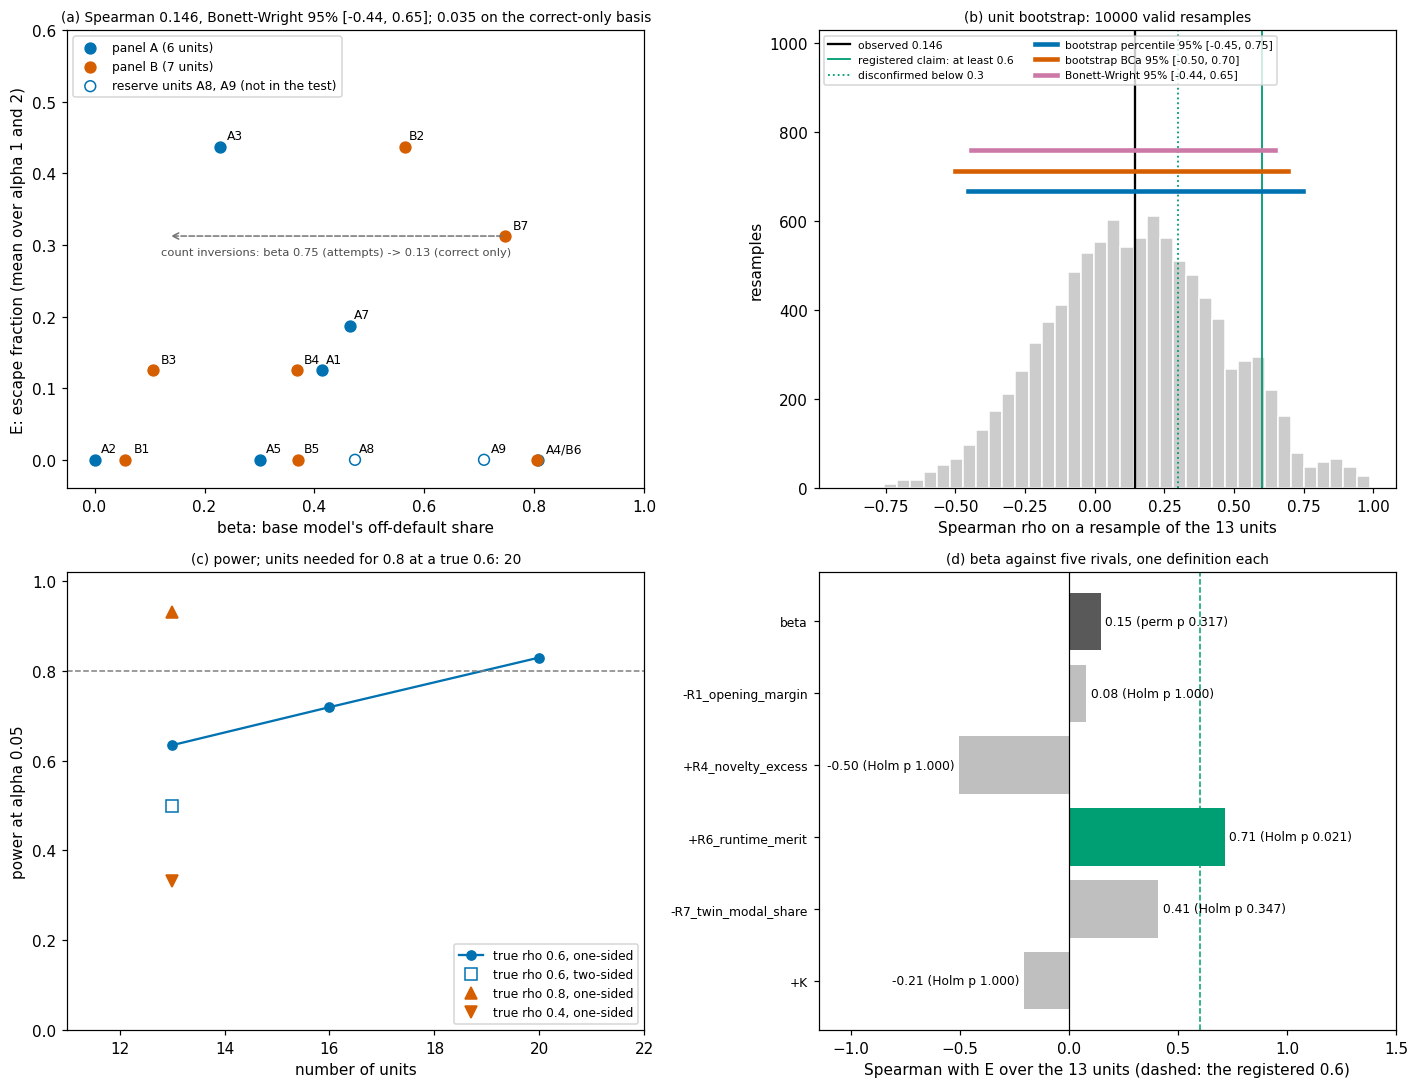

In [14]:
# ---- Results: every recomputed number beside the full run's (results/0c.json) ----
ref = data["reference_full_run"]["results_0c"]
pw, rpw = out["power"], ref["power"]


def _f(v):
    if v is None:
        return "n/a"
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(_f(u) for u in v) + "]"
    return f"{v:.4g}" if isinstance(v, float) else str(v)


summary = [
    ("Spearman rho(beta, E), 13 units", out["rho"], ref["rho"]),
    ("one-sided permutation p", out["perm"]["p"], ref["perm"]["p"]),
    ("Fisher-z 95%, plain", out["ci"]["plain"], ref["ci"]["plain"]),
    ("Fisher-z 95%, Fieller", out["ci"]["fieller"], ref["ci"]["fieller"]),
    ("Fisher-z 95%, Bonett-Wright", out["ci"]["bonett_wright"], ref["ci"]["bonett_wright"]),
    ("bootstrap 95%, percentile", out["boot"]["percentile"], ref["boot"]["percentile"]),
    ("bootstrap 95%, BCa", out["boot"]["bca"], ref["boot"]["bca"]),
    ("rho, count inversions' beta correct-only", out["sens_correct_only_basis"]["rho"], ref["sens_correct_only_basis"]["rho"]),
    ("rho over 15 units (with A8, A9)", out["sens15"]["rho"], ref["sens15"]["rho"]),
    ("power at a true 0.6, one-sided / two-sided", [pw["0.6"]["power"], pw["0.6"]["power_two_sided"]],
     [rpw["0.6"]["power"], rpw["0.6"]["power_two_sided"]]),
    ("power at a true 0.4 / 0.8, one-sided", [pw["0.4"]["power"], pw["0.8"]["power"]],
     [rpw["0.4"]["power"], rpw["0.8"]["power"]]),
    ("units needed for power 0.8 at 0.6", pw["n_for_0.8_at_0.6"], rpw["n_for_0.8_at_0.6"]),
] + [(f"rival {k}: rho with E / Holm p", [v["rho_with_E"], v["holm_p"]],
      [ref["rivals"][k]["rho_with_E"], ref["rivals"][k]["holm_p"]]) for k, v in out["rivals"].items()]
print(f"{'quantity':<50}{'this run':>28}{'full run':>28}")
for name, mine, full in summary:
    print(f"{name:<50}{_f(mine):>28}{_f(full):>28}")

# ---- The geometry of the test ----
rows_all = movability_units()
core = [r for r in rows_all if r["core13"]]
reserve = [r for r in rows_all if not r["core13"]]
fig, axs = plt.subplots(2, 2, figsize=(13, 10), dpi=110)

# (a) the units in the plane of beta and E; units at the same point share one label
ax = axs[0, 0]
for panel, color in (("A", "#0072B2"), ("B", "#D55E00")):
    pts = [r for r in core if r["panel"] == panel]
    ax.scatter([r["beta"] for r in pts], [r["E"] for r in pts], color=color, s=50, zorder=3,
               label=f"panel {panel} ({len(pts)} units)")
ax.scatter([r["beta"] for r in reserve], [r["E"] for r in reserve], facecolors="none", edgecolors="#0072B2", s=50,
           zorder=3, label="reserve units A8, A9 (not in the test)")
groups = {}
for r in core + reserve:
    groups.setdefault((round(r["beta"], 2), round(r["E"], 3)), []).append(r["unit"])
for (bx, ey), units in groups.items():
    ax.annotate("/".join(units), (bx, ey), fontsize=8, xytext=(4, 5), textcoords="offset points")
b7 = next(r for r in core if r["beta_source"] == "attempt")
ax.annotate("", xy=(b7["beta_correct_only"], b7["E"]), xytext=(b7["beta"], b7["E"]),
            arrowprops=dict(arrowstyle="->", linestyle="--", color="0.45"))
ax.text((b7["beta"] + b7["beta_correct_only"]) / 2, b7["E"] - 0.015,
        f"{b7['name']}: beta {b7['beta']:.2f} (attempts) -> {b7['beta_correct_only']:.2f} (correct only)",
        fontsize=7.5, ha="center", va="top", color="0.3")
ci = out["ci"]["bonett_wright"]
ax.set_xlabel("beta: base model's off-default share")
ax.set_ylabel("E: escape fraction (mean over alpha 1 and 2)")
ax.set_xlim(-0.05, 1.0)
ax.set_ylim(-0.04, 0.6)
ax.set_title(f"(a) Spearman {out['rho']:.3f}, Bonett-Wright 95% [{ci[0]:.2f}, {ci[1]:.2f}]; "
             f"{out['sens_correct_only_basis']['rho']:.3f} on the correct-only basis", fontsize=9)
ax.legend(fontsize=8, loc="upper left")

# (b) the unit bootstrap of rho: the same resamples stage_0c drew (seed 2)
ax = axs[0, 1]
x, y = [r["beta"] for r in core], [r["E"] for r in core]
samples = X.bootstrap_spearman(x, y, n_boot=N_BOOT, seed=2)["samples"]
samples = samples[np.isfinite(samples)]
ax.hist(samples, bins=40, color="0.8", edgecolor="white")
ax.axvline(out["rho"], color="k", lw=1.5, label=f"observed {out['rho']:.3f}")
ax.axvline(0.6, color="#009E73", lw=1.2, label="registered claim: at least 0.6")
ax.axvline(0.3, color="#009E73", lw=1.2, ls=":", label="disconfirmed below 0.3")
top = ax.get_ylim()[1]
for j, (lab, (lo, hi), col) in enumerate((("bootstrap percentile", out["boot"]["percentile"], "#0072B2"),
                                         ("bootstrap BCa", out["boot"]["bca"], "#D55E00"),
                                         ("Bonett-Wright", out["ci"]["bonett_wright"], "#CC79A7"))):
    ax.plot([lo, hi], [top * (1.04 + 0.07 * j)] * 2, color=col, lw=3, label=f"{lab} 95% [{lo:.2f}, {hi:.2f}]")
ax.set_ylim(0, top * 1.6)
ax.set_xlabel("Spearman rho on a resample of the 13 units")
ax.set_ylabel("resamples")
ax.set_title(f"(b) unit bootstrap: {len(samples)} valid resamples", fontsize=9)
ax.legend(fontsize=7, loc="upper left", ncol=2)

# (c) power of the registered one-sided permutation test (Gaussian copula with the observed margins)
ax = axs[1, 0]
ns = [13] + [int(k) for k in pw["curve_rho0.6"]]
ps = [pw["0.6"]["power"]] + list(pw["curve_rho0.6"].values())
ax.plot(ns, ps, "o-", color="#0072B2", label="true rho 0.6, one-sided")
ax.plot([13], [pw["0.6"]["power_two_sided"]], "s", mfc="none", color="#0072B2", ms=8, label="true rho 0.6, two-sided")
for rs, mk in (("0.8", "^"), ("0.4", "v")):
    ax.plot([13], [pw[rs]["power"]], mk, color="#D55E00", ms=8, label=f"true rho {rs}, one-sided")
ax.axhline(0.8, color="0.5", ls="--", lw=1)
ax.set_xlim(11, max(ns) + 2)
ax.set_ylim(0, 1.02)
ax.set_xlabel("number of units")
ax.set_ylabel("power at alpha 0.05")
ax.set_title(f"(c) power; units needed for 0.8 at a true 0.6: {pw['n_for_0.8_at_0.6']}", fontsize=9)
ax.legend(fontsize=8, loc="lower right")

# (d) beta and the five rivals, each signed so that the predicted direction is positive
ax = axs[1, 1]
names = ["beta"] + [("-" if v["sign"] < 0 else "+") + k for k, v in out["rivals"].items()]
rhos = [out["rho"]] + [v["rho_with_E"] for v in out["rivals"].values()]
pvals = [out["perm"]["p"]] + [v["holm_p"] for v in out["rivals"].values()]
yy = np.arange(len(names))[::-1]
ax.barh(yy, rhos, color=["0.35"] + ["#009E73" if v["holm_p"] < 0.05 else "0.75" for v in out["rivals"].values()])
for yv, rv, pv, nm in zip(yy, rhos, pvals, names):
    ax.text(rv + (0.02 if rv >= 0 else -0.02), yv, f"{rv:.2f} ({'perm p' if nm == 'beta' else 'Holm p'} {fmtp(pv)})",
            va="center", ha="left" if rv >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.axvline(0.6, color="#009E73", lw=1, ls="--")
ax.set_yticks(yy)
ax.set_yticklabels(names, fontsize=8)
ax.set_xlim(-1.15, 1.5)
ax.set_xlabel("Spearman with E over the 13 units (dashed: the registered 0.6)")
ax.set_title("(d) beta against five rivals, one definition each", fontsize=9)
fig.tight_layout()
plt.show()

## Reading the result

- **Beta is not a strong predictor, but a moderate relation is not ruled out.** With 13 units, and 6 of them tied at E = 0 because they never moved, a Spearman of 0.15 has a 95% interval from about -0.44 to 0.65. Even a true Spearman of 0.6 would be detected only about 63% of the time, and about 20 units would be needed for 80% power.
- **The pooled value leans on one unit.** Count inversions entered with a beta of 0.75 taken from attempts, because only a few of its base programs were correct; 67% of those attempts are unlabelled "other". On the correct-only basis used for the other twelve units its beta is 0.13, and Spearman falls to 0.035.
- **Only the runtime merit R6 survives Holm correction among the rivals.** Tasks where a faster non-default algorithm exists move more. Even so, the paired interval for rho(beta) - rho(R6) includes 0.
- **The verdict is bf16-conditional.** The escape fractions were measured with the bf16 engine, and stage 0a found that some 8-bit plan-noise effects did not replicate in bf16.
